In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Data Collection

In [28]:
df = pd.read_csv(r"C:\Users\SAHU\OneDrive\Desktop\Data Analytic\Internship - IIM SKIlLS\Intership 30-10-2026\3rd Project\hotel_bookings.csv")

# Data Assessing

In [36]:
# Data profiling
df.head()
df.tail()
df.shape
df.columns
df.info()
df.describe()
df.describe(include = 'object')

# Missing Values
df.isna().sum()
((df.isna().sum()/df.shape[0])*100)[df.isna().sum()>0]

# Outlier Detection
# Select relevant numerical columns
num_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests'
]

# Create an empty list to store results
outlier_results = []

# Detect outliers in each column
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        'Column': col,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier Percentage': len(outliers) / len(df) * 100
    })

# Display the summary
outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

# For inconsistence values
col = ['hotel','meal','market_segment','distribution_channel','reserved_room_type','assigned_room_type','deposit_type','customer_type','reservation_status']

for c in col:
    print(df[c].value_counts())
    print("-"*50)

# For duplicated values
df.duplicated().sum()
df[df.duplicated()]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,Column,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,lead_time,-195.00,373.00,3005,2.52
1,stays_in_weekend_nights,-3.00,5.00,265,0.22
2,stays_in_week_nights,-2.00,6.00,3354,2.81
3,adults,2.00,2.00,29710,24.88
4,children,0.00,0.00,8590,7.19
5,babies,0.00,0.00,917,0.77
6,previous_cancellations,0.00,0.00,6484,5.43
7,previous_bookings_not_canceled,0.00,0.00,3620,3.03
8,booking_changes,0.00,0.00,18076,15.14
9,days_in_waiting_list,0.00,0.00,3698,3.10


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64
--------------------------------------------------
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64
--------------------------------------------------
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64
--------------------------------------------------
distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64
--------------------------------------------------
reserved_room_type
A    85994
D    19201
E     6535
F     2897
G     2094
B     1118
C      932
H      601
P       12
L        6
Name: count, dtype: int64
--------------------------------------------------
assigned_room_type
A 

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119349,City Hotel,0,186,2017,August,35,31,0,3,2,...,No Deposit,9.0,NaN,0,Transient,126.00,0,2,Check-Out,2017-09-03
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03



# Data Profiling and Data Quality Assessment

## 1. Dataset Overview

- The dataset contains **119,390 rows and 32 columns**, providing a substantial volume of hotel booking records for analysis.
- The dataset contains **16 integer columns, 4 floating-point columns, and 12 object columns**.
- The `hotel` column identifies two hotel categories: City Hotel and Resort Hotel.
- The `reservation_status_date` column is stored as an object data type and should be converted to datetime format before date-based analysis.
- The dataset covers arrival years from 2015 to 2017.

## 2. Missing-Value Assessment

- The dataset contains missing values in four columns: `company`, `agent`, `country`, and `children`.
- The `company` column has **112,593 missing values (94.31%)**, making it the column with the most substantial missing-data problem.
- The `agent` column contains **16,340 missing values (13.69%)**.
- The `country` column contains **488 missing values (0.41%)**.
- The `children` column contains only **4 missing values (approximately 0.003%)**.
- Missing values should be investigated according to their business meaning. In particular, missing company or agent information should not automatically be replaced with zero because missing information does not necessarily mean that no company or agent was involved.

## 3. Outlier Detection

- The IQR method identified potential outliers in all 13 numerical columns examined.
- The `lead_time` column contains **3,005 flagged records (2.52%)**, indicating unusually long booking lead times under the IQR rule.
- The `stays_in_week_nights` column contains **3,354 flagged records (2.81%)**.
- The `adr` column contains **3,793 flagged records (3.18%)**.
- The `booking_changes` column contains **18,076 flagged records (15.14%)**.
- The `adults` column contains **29,710 flagged records (24.88%)**. However, its first and third quartiles are both 2, resulting in an IQR of zero.
- Similar zero-IQR behavior occurs in several other count-based columns. Consequently, the IQR method can flag ordinary non-modal values rather than genuine data errors.
- The `adr` column ranges from **-6.38 to 5,400**. These extreme values require further business investigation before any records are changed or removed.
- Outlier detection identifies unusual observations; it does not establish that those observations are incorrect.

## 4. Categorical-Value Assessment

- The `hotel` column contains two categories: City Hotel and Resort Hotel.
- The most frequent meal category is `BB`, with **92,310 records**.
- The most frequent market segment is `Online TA`, with **56,477 records**.
- The most frequent distribution channel is `TA/TO`, with **97,870 records**.
- The most frequent deposit type is `No Deposit`, with **104,641 records**.
- The most frequent customer type is `Transient`, with **89,613 records**.
- The `market_segment`, `distribution_channel`, and `meal` columns contain `Undefined` values. These should be investigated to determine whether they represent legitimate categories or missing/uncategorized information.
- Reserved and assigned room types have different category distributions, which can be examined in later booking and room-allocation analyses.

## 5. Duplicate-Record Assessment

- The dataset contains **31,994 extra duplicate rows** when exact duplicates are identified across all 32 columns.
- When every row belonging to a duplicate group is included, **40,165 rows** belong to groups containing repeated identical records.
- These two counts differ because the second calculation includes the first occurrence of each duplicate group.
- Exact duplicates should be investigated before deletion. Repeated records may affect booking counts, cancellation rates, and revenue-related summaries if they are unintended duplicates.
- The original dataset should be preserved until the duplication issue has been reviewed and a cleaning decision has been documented.

## 6. Overall Data-Quality Conclusion

- The dataset provides a strong foundation for hotel booking analysis, but it requires further quality assessment before business conclusions are finalized.
- The main issues identified are substantial missingness in `company`, missing values in `agent`, exact duplicate records, unusual numerical values, and categorical values labeled `Undefined`.
- The data types should be reviewed, particularly the reservation-status date column.
- Outliers should be assessed using business rules in addition to statistical methods.
- Missing values, duplicate records, and unusual observations should be handled according to documented decisions rather than removed automatically.

## 7. Recommended Next Steps

- Investigate the 31,994 extra duplicate rows before deciding whether to remove them.
- Assess missing values in `company` and `agent` and determine whether missingness has a business meaning.
- Validate negative and unusually high `adr` values.
- Review zero-IQR outlier results using domain-specific rules.
- Convert date columns to appropriate datetime types.
- Re-run the data-quality checks after cleaning and document the changes made.

**Final conclusion:** The initial profiling identifies several important data-quality issues that should be investigated before proceeding to reliable hotel booking, cancellation, and revenue-related analysis.


# Data Pre-Processing

In [40]:
# Dealing with the outliers
COL = ['lead_time','stays_in_weekend_nights','stays_in_week_nights','total_of_special_requests','adr']

for C in COL:
    Q1 = df[C].quantile(0.25)
    Q3 = df[C].quantile(0.75)
    IQR = Q3 - Q1
    LW = Q1 - 1.5 * IQR
    UW = Q3 + 1.5 * IQR
    df[C] = df[C].mask((df[C]<LW) | (df[C]>UW),0)

In [50]:
# Filling the null value
df['children'] = df['children'].fillna(df['children'].mean())
df['country'] = df['country'].fillna(df['country'].mode()[0])
df['agent'] = df['agent'].fillna(df['agent'].mode()[0])

# Dropping the company column
df.drop('company', axis=1,inplace=True)

In [56]:
# Removing duplicates
df = df.drop_duplicates()

In [53]:
# Verifying the above steps
df.info()
df.shape
df.duplicated().sum()

(119390, 31)

# Data Pre-processing

## 1. Outlier Treatment

- The IQR method was applied to five numerical columns: `lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, `total_of_special_requests`, and `adr`.
- The first quartile (Q1), third quartile (Q3), and interquartile range (IQR) were calculated for each selected column.
- Lower and upper bounds were determined using the 1.5 × IQR rule to identify potential outliers.
- Values falling outside these bounds were replaced with **0** using the Pandas `mask()` function.
- This operation modifies extreme values but does not remove the corresponding booking records.
- Replacing outliers with zero the values could be 0 and more but could never be in negative values.

## 2. Missing-Value Treatment

- Missing values in the `children` column were replaced with the column mean.
- Missing values in the `country` column were filled with the most frequently occurring country using the mode.
- Missing values in the `agent` column were filled with the most frequently occurring agent identifier using the mode.
- These operations were performed using Pandas `fillna()` to reduce missing values in the selected columns.
- Mean and mode imputation provide simple replacement methods but may introduce bias into the analysis.
- Since `children` represents a count, the imputed mean should be checked to ensure that the resulting values remain valid for this variable.
- The `company` column was handled separately because it contained a substantial proportion of missing values.

## 3. Removal of the Company Column

- The `company` column was removed from the dataset because `company` column is containing null values more than 50%, if we are going to fill null values on basis of imputation that it could mislead critical information.

## 4. Duplicate Record Removal

- Exact duplicate rows were removed using the Pandas `drop_duplicates()` function.
- The cleaned result was assigned back to the DataFrame to update the dataset.
- Removing duplicate records helps reduce the risk of counting identical observations more than once.
- This operation removes rows that match across all columns; it does not identify every possible duplicate booking based on booking identifiers.
- The number of remaining records should be checked after removal to confirm the outcome.
- Duplicate removal should be validated against the business context to avoid accidentally excluding legitimate repeated records.

## 5. Post-Cleaning Verification

- The `df.info()` function was used to inspect column names, data types, non-null counts, and memory usage.
- The `df.shape` attribute was used to determine the final number of rows and columns after cleaning.
- The `df.duplicated().sum()` function was used to count any remaining exact duplicate rows.
- These checks help verify the structural changes made during data cleaning.
- The final missing-value counts should also be examined to confirm that the selected imputation operations were successful.

## 6. Overall Conclusion

- Initial data-cleaning operations were performed to improve the quality and consistency of the Hotel Booking Demand dataset.
- Potential outliers were treated, selected missing values were imputed, the `company` column was removed, and exact duplicate rows were eliminated.
- Dataset structure and remaining duplicates were checked using Pandas verification functions.
- The dataset is prepared for the next stage of analysis, subject to validation of the cleaning decisions and their impact on the original data.
- Further exploratory data analysis will help identify hotel booking patterns, cancellation trends, customer behavior, and other meaningful business insights.

In [59]:
# Ghost Guest Audit

ghost_guest = df[
    (df['adults'] + df['children'] + df['babies']) == 0
]

print("Ghost guest records:", len(ghost_guest))
print("Percentage:", round(len(ghost_guest) / len(df) * 100, 2), "%")

ghost_guest.head()

Ghost guest records: 166
Percentage: 0.19 %


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,1,No Deposit,9.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,0,No Deposit,9.0,0,Transient,0.0,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,0,No Deposit,38.0,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,1,No Deposit,308.0,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,1,No Deposit,308.0,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05


In [60]:
# Financial Anomaly Extraction

financial_anomaly = df[
    (df['is_canceled'] == 0) &
    (df['adr'] <= 0)
]

print("Financial anomaly records:", len(financial_anomaly))
print("Percentage:", round(len(financial_anomaly) / len(df) * 100, 2), "%")

financial_anomaly.head()

Financial anomaly records: 3824
Percentage: 4.38 %


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,9.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,0,2015,July,27,1,0,0,2,...,4,No Deposit,9.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
125,Resort Hotel,0,32,2015,July,27,4,0,1,4,...,2,No Deposit,9.0,0,Transient,0.0,0,1,Check-Out,2015-07-05
140,Resort Hotel,0,44,2015,July,28,5,2,0,3,...,3,No Deposit,240.0,0,Transient,0.0,2,0,Check-Out,2015-07-07
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,0,No Deposit,240.0,0,Transient,0.0,0,2,Check-Out,2015-07-06


In [61]:
# Temporal Feature Aggregation

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',
    errors='coerce'
)

df[['arrival_date_year', 'arrival_date_month',
    'arrival_date_day_of_month', 'arrival_date']].head()

C:\Users\SAHU\AppData\Local\Temp\ipykernel_18676\4256704013.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['arrival_date'] = pd.to_datetime(


,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


In [63]:
# Deposit Policy Analysis

df.groupby('deposit_type')['is_canceled'].agg(
    ['count', 'sum', 'mean']
).assign(
    cancellation_percentage=lambda x: x['mean'] * 100
)

,count,sum,mean,cancellation_percentage
deposit_type,,,,
No Deposit,86194,23006,0.266910,26.690953
Non Refund,1038,983,0.947013,94.701349
Refundable,107,26,0.242991,24.299065


In [64]:
# Lead Time Risk Analysis

df.groupby('lead_time')['is_canceled'].mean().mul(100).reset_index(
    name='cancellation_percentage'
)

,lead_time,cancellation_percentage
0,0,8.716372
1,1,6.660442
2,2,9.459459
3,3,9.976526
4,4,9.821429
...,...,...
368,368,77.777778
369,370,0.000000
370,371,100.000000
371,372,100.000000


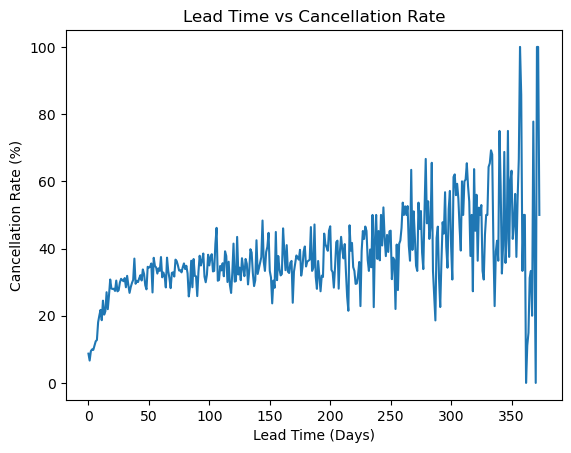

In [65]:
import matplotlib.pyplot as plt

df.groupby('lead_time')['is_canceled'].mean().mul(100).plot()

plt.xlabel('Lead Time (Days)')
plt.ylabel('Cancellation Rate (%)')
plt.title('Lead Time vs Cancellation Rate')
plt.show()

In [66]:
# Customer Segment Analysis

df.groupby('customer_type')['is_canceled'].value_counts(
    normalize=True
).mul(100).unstack(fill_value=0)

is_canceled,0,1
customer_type,,
Contract,83.683875,16.316125
Group,90.073529,9.926471
Transient,69.891726,30.108274
Transient-Party,84.739539,15.260461


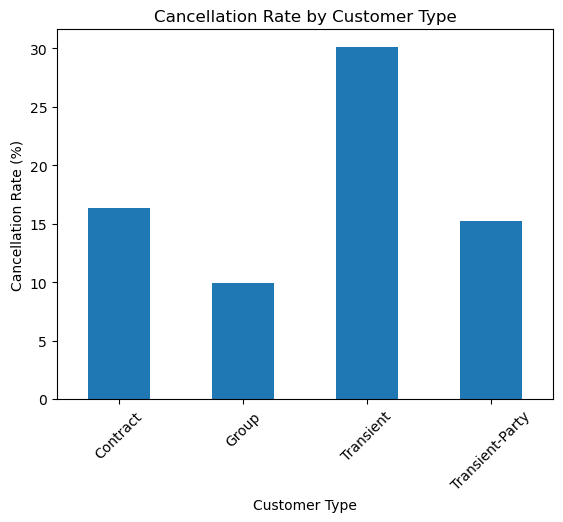

In [67]:
df.groupby('customer_type')['is_canceled'].mean().mul(100).plot(
    kind='bar'
)

plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate (%)')
plt.title('Cancellation Rate by Customer Type')
plt.xticks(rotation=45)
plt.show()

# Booking Cancellation and Customer Risk Analysis

## 1. Deposit Policy Efficacy

- Calculated the total number of bookings and cancellations for each `deposit_type`.
- Computed cancellation percentages for `No Deposit`, `Non Refund`, and `Refundable` booking categories.
- Compared cancellation rates across deposit policies to identify differences in cancellation behavior.
- Evaluated whether bookings with non-refundable deposits exhibit lower cancellation rates than other deposit categories.
- Identified the deposit category with the highest cancellation percentage to support further investigation.
- **Business Insight:** Cancellation rates can help evaluate the relationship between deposit policies and booking cancellations; however, differences alone do not prove that a deposit policy causes cancellations to decrease.

## 2. Lead Time Risk Cut-off

- Analyzed the relationship between `lead_time` and `is_canceled` to understand how booking lead time relates to cancellation behavior.
- Calculated cancellation percentages for different lead-time values.
- Visualized the relationship between lead time and cancellation rate using a line chart.
- Examined whether bookings made further in advance tend to have higher cancellation rates.
- Identified potential lead-time ranges associated with increased cancellation risk.
- **Business Insight:** Understanding cancellation patterns across lead-time ranges can help hotels improve booking monitoring, demand planning, and room inventory management.
- A reliable operational risk threshold should be selected using observed data and a clearly defined business criterion rather than assuming a universal cutoff.

## 3. Customer Segment Volatility

- Analyzed cancellation behavior across different `customer_type` categories.
- Calculated the relative frequency of canceled and non-canceled bookings within each customer segment.
- Compared cancellation percentages across customer types using a bar chart.
- Identified the customer segment with the highest cancellation rate.
- Used normalized frequencies to compare cancellation behavior fairly across segments of different sizes.
- **Business Insight:** Customer segments with higher cancellation rates may require closer monitoring and targeted booking policies.
- Cancellation percentages should be interpreted alongside booking volumes to distinguish high cancellation risk from high cancellation counts.

## 4. Overall Conclusion

- Evaluated booking cancellation patterns across deposit policies, lead-time values, and customer segments.
- Identified differences in cancellation behavior that may support hotel revenue management and operational planning.
- Highlighted potential high-risk booking categories for further investigation.
- These findings describe associations and do not independently establish causal relationships.
- Further analysis of market segments, booking channels, hotel types, and seasonal patterns can help validate the findings and develop evidence-based business recommendations.

In [69]:
# Distribution Channel Analysis

df.groupby('distribution_channel').agg(
    total_bookings=('adr', 'count'),
    avg_adr=('adr', 'mean'),
    cancellation_rate=('is_canceled', 'mean')
).assign(
    cancellation_rate=lambda x: x['cancellation_rate'] * 100
).round(2)

,total_bookings,avg_adr,cancellation_rate
distribution_channel,,,
Corporate,5071,68.23,12.78
Direct,12980,91.86,14.83
GDS,181,117.91,19.89
TA/TO,69102,98.86,30.97
Undefined,5,46.24,80.00


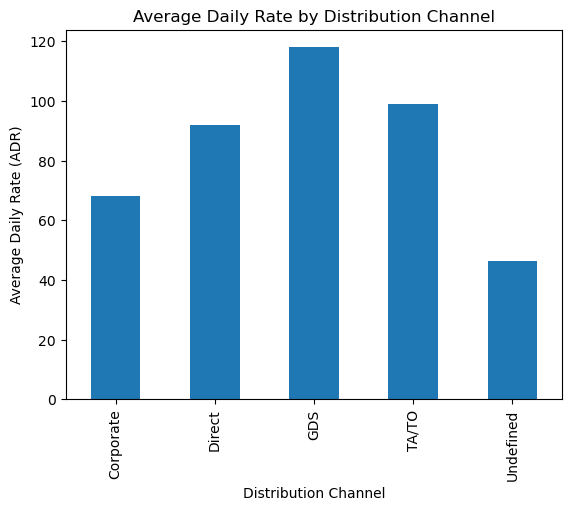

In [71]:
df.groupby('distribution_channel')['adr'].mean().plot(kind='bar')

plt.title('Average Daily Rate by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Average Daily Rate (ADR)')
plt.show()

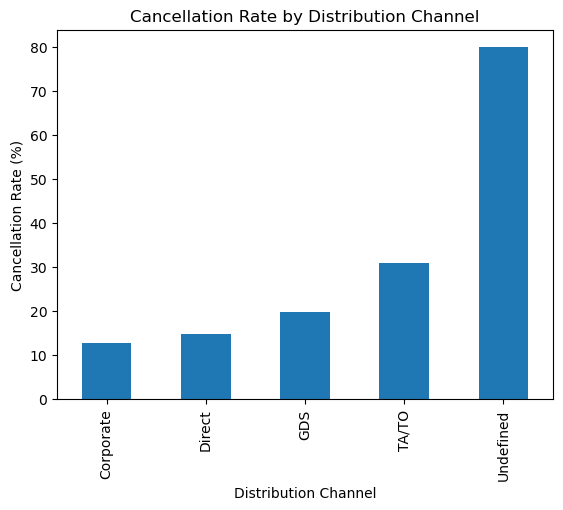

In [72]:
df.groupby('distribution_channel')['is_canceled'].mean().mul(100).plot(kind='bar')

plt.title('Cancellation Rate by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Cancellation Rate (%)')
plt.show()

In [73]:
# Room Allocation Discrepancy Audit

room_change = df[
    df['reserved_room_type'] != df['assigned_room_type']
]

print("Room discrepancy records:", len(room_change))
room_change.head()

Room discrepancy records: 13096


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,9.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01
12,Resort Hotel,0,68,2015,July,27,1,0,4,2,...,No Deposit,240.0,0,Transient,97.00,0,0,Check-Out,2015-07-05,2015-07-01
15,Resort Hotel,0,68,2015,July,27,1,0,4,2,...,No Deposit,240.0,0,Transient,97.00,0,0,Check-Out,2015-07-05,2015-07-01
17,Resort Hotel,0,12,2015,July,27,1,0,1,2,...,No Deposit,240.0,0,Transient,88.20,0,0,Check-Out,2015-07-02,2015-07-01
18,Resort Hotel,0,0,2015,July,27,1,0,1,2,...,No Deposit,9.0,0,Transient,107.42,0,0,Check-Out,2015-07-02,2015-07-01


In [74]:
room_change.groupby('is_canceled').size()

is_canceled
0    12479
1      617
dtype: int64

In [75]:
# Create room-change category

df['room_changed'] = (
    df['reserved_room_type'] != df['assigned_room_type']
)

df.groupby('room_changed')['is_canceled'].mean().mul(100)

C:\Users\SAHU\AppData\Local\Temp\ipykernel_18676\703897616.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['room_changed'] = (


room_changed
False    31.515429
True      4.711362
Name: is_canceled, dtype: float64

In [76]:
df.groupby('room_changed')['is_repeated_guest'].mean().mul(100)

room_changed
False    3.200302
True     7.926084
Name: is_repeated_guest, dtype: float64

In [77]:
# Summary by room allocation status

df.groupby('room_changed').agg(
    total_bookings=('is_canceled', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    repeat_guest_rate=('is_repeated_guest', 'mean')
).mul(100).round(2)

,total_bookings,cancellation_rate,repeat_guest_rate
room_changed,,,
False,7424300,31.52,3.20
True,1309600,4.71,7.93


In [78]:
summary = df.groupby('room_changed').agg(
    total_bookings=('is_canceled', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    repeat_guest_rate=('is_repeated_guest', 'mean')
)

summary['cancellation_rate'] *= 100
summary['repeat_guest_rate'] *= 100

summary.round(2)

,total_bookings,cancellation_rate,repeat_guest_rate
room_changed,,,
False,74243,31.52,3.20
True,13096,4.71,7.93


# Multivariate Channel Economics & Operational Overbooking

## 1. Distribution Channel Margin Grid

- Grouped booking records by `distribution_channel` to compare the performance of different booking channels.
- Calculated the total number of bookings for each distribution channel.
- Calculated the average daily rate (`adr`) to compare average booking rates across channels.
- Calculated cancellation rates using `is_canceled` and converted them into percentages.
- Visualized average daily rates across distribution channels using a bar chart.
- Visualized cancellation percentages across distribution channels using a separate bar chart.
- Identified channels with relatively high ADR and cancellation rates for further investigation.
- **Business Insight:** Distribution channels with higher ADR may generate more revenue per occupied room, but cancellation rates and commission costs must also be considered when evaluating profitability.
- **Limitation:** ADR alone cannot determine profitability. Channel commissions, completed stays, and operating costs are needed for a reliable margin analysis.

## 2. Room Allocation Discrepancy Audit

- Compared `reserved_room_type` and `assigned_room_type` to identify bookings where the assigned room differed from the reserved room.
- Created a filtered dataset containing bookings with room allocation discrepancies.
- Counted the number of records where reserved and assigned room types differed.
- Created a Boolean column named `room_changed` to classify bookings according to room allocation differences.
- Calculated cancellation rates for bookings with and without room allocation discrepancies.
- Calculated repeat-guest percentages using `is_repeated_guest` to compare customer loyalty between the two groups.
- **Business Insight:** Differences in cancellation rates and repeat-guest percentages may reveal patterns associated with room allocation practices and customer behavior.
- **Limitation:** A room allocation discrepancy does not necessarily indicate an operational error or customer dissatisfaction. Further investigation is needed to understand the reasons behind these differences.

## 3. Room Allocation Performance Summary

- Grouped bookings by `room_changed` to compare bookings with and without room allocation discrepancies.
- Calculated the total number of bookings in each group.
- Calculated cancellation rates and repeat-guest rates for both groups.
- Converted cancellation and repeat-guest rates into percentages for easier interpretation.
- Kept booking counts separate from percentage calculations to preserve accurate results.
- Compared both groups to identify differences in cancellation behavior and repeat-guest patterns.

## 4. Overall Conclusion

- Evaluated distribution channel performance using booking volumes, average daily rates, and cancellation percentages.
- Examined room allocation discrepancies and their association with cancellations and repeat-guest behavior.
- Identified channel and room allocation patterns that may require further business investigation.
- Recognized that a higher ADR does not necessarily indicate higher profitability.
- Recognized that room allocation differences do not automatically represent operational failures.
- Interpreted the findings as associations rather than proven causal relationships.
- Further analysis of completed stays, channel commissions, realized revenue, and customer feedback can support more reliable hotel revenue management and operational decisions.

In [79]:
# Calculate Lost Revenue

df['lost_revenue'] = (
    df['adr'] *
    (df['stays_in_week_nights'] + df['stays_in_weekend_nights'])
)

df.loc[df['is_canceled'] == 1, 'lost_revenue'].sum()

C:\Users\SAHU\AppData\Local\Temp\ipykernel_18676\3104730971.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['lost_revenue'] = (


np.float64(8896086.240000002)

In [80]:
# Function to Calculate Total Lost Revenue

def total_lost_revenue(df):
    canceled = df[df['is_canceled'] == 1]

    loss = (
        canceled['adr'] *
        (canceled['stays_in_week_nights'] +
         canceled['stays_in_weekend_nights'])
    )

    return loss.sum()

print("Total Estimated Lost Revenue:", total_lost_revenue(df))

Total Estimated Lost Revenue: 8896086.240000002


In [81]:
# Lost Revenue by Hotel

df[df['is_canceled'] == 1].groupby('hotel')['lost_revenue'].sum().sort_values(ascending=False)

hotel
City Hotel      5754934.38
Resort Hotel    3141151.86
Name: lost_revenue, dtype: float64

In [82]:
# Lost Revenue by Market Segment

df[df['is_canceled'] == 1].groupby('market_segment')['lost_revenue'].sum().sort_values(ascending=False)

market_segment
Online TA        7205764.73
Offline TA/TO     681904.64
Direct            612981.88
Groups            287226.75
Corporate          95655.25
Aviation           12235.00
Complementary        269.99
Undefined             48.00
Name: lost_revenue, dtype: float64

In [83]:
# Lost Revenue by Hotel and Market Segment

df[df['is_canceled'] == 1].groupby(
    ['hotel', 'market_segment']
)['lost_revenue'].sum().sort_values(ascending=False)

hotel         market_segment
City Hotel    Online TA         4878388.07
Resort Hotel  Online TA         2327376.66
              Offline TA/TO      344986.11
City Hotel    Offline TA/TO      336918.53
Resort Hotel  Direct             316418.63
City Hotel    Direct             296563.25
              Groups             181310.32
Resort Hotel  Groups             105916.43
City Hotel    Corporate           49276.22
Resort Hotel  Corporate           46379.03
City Hotel    Aviation            12235.00
              Complementary         194.99
Resort Hotel  Complementary          75.00
City Hotel    Undefined              48.00
Name: lost_revenue, dtype: float64

In [84]:
# Lost Revenue by Hotel and Market Segment

df[df['is_canceled'] == 1].groupby(
    ['hotel', 'market_segment']
)['lost_revenue'].sum().sort_values(ascending=False)

hotel         market_segment
City Hotel    Online TA         4878388.07
Resort Hotel  Online TA         2327376.66
              Offline TA/TO      344986.11
City Hotel    Offline TA/TO      336918.53
Resort Hotel  Direct             316418.63
City Hotel    Direct             296563.25
              Groups             181310.32
Resort Hotel  Groups             105916.43
City Hotel    Corporate           49276.22
Resort Hotel  Corporate           46379.03
City Hotel    Aviation            12235.00
              Complementary         194.99
Resort Hotel  Complementary          75.00
City Hotel    Undefined              48.00
Name: lost_revenue, dtype: float64

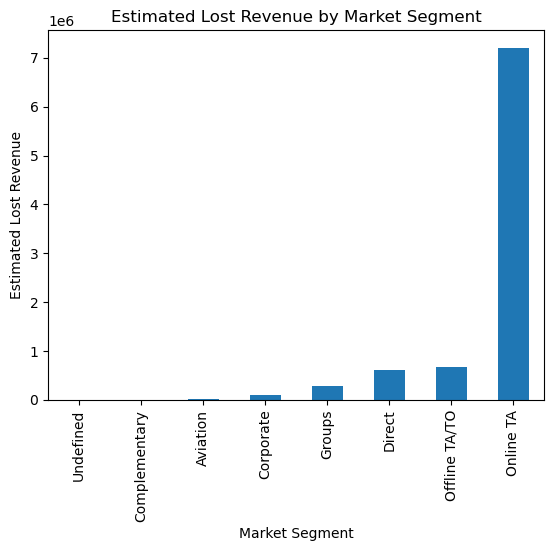

In [85]:
# Visualization of Lost Revenue by Market Segment

import matplotlib.pyplot as plt

df[df['is_canceled'] == 1].groupby(
    'market_segment'
)['lost_revenue'].sum().sort_values().plot(kind='bar')

plt.title('Estimated Lost Revenue by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Estimated Lost Revenue')
plt.show()

## Conclusion: Cancellation-Related Revenue Loss Analysis

- **Lost Revenue Calculation:** Estimated cancellation-related revenue loss by multiplying `adr` by the total number of recorded weekday and weekend stay nights for canceled bookings (`is_canceled == 1`).

- **Total Estimated Revenue Loss:** Created a Python function to calculate and aggregate the estimated revenue associated with canceled bookings across the dataset.

- **Hotel-Wise Analysis:** Compared estimated cancellation-related revenue loss between City Hotel and Resort Hotel to identify which hotel type contributes the largest estimated loss.

- **Market Segment Analysis:** Aggregated estimated revenue loss across `market_segment` categories to identify segments associated with the highest cancellation-related revenue loss.

- **Combined Business Analysis:** Grouped the results by `hotel` and `market_segment` to identify specific business segments requiring further investigation.

- **Data Visualization:** Created a bar chart to compare estimated revenue loss across market segments and make differences easier to interpret.

- **Business Insight:** Hotel types and market segments with higher estimated losses may require closer monitoring of cancellation patterns, booking policies, and pricing strategies.

- **Strategic Recommendation:** Investigate high-loss segments and evaluate targeted deposit policies, cancellation conditions, and pricing adjustments before implementing business changes.

- **Limitation:** The calculated amount represents an estimate based on ADR and recorded stay nights, not confirmed actual revenue lost. Some canceled rooms may be resold, and the recorded stay duration may not equal the stay that would have occurred.

- **Overall Conclusion:** This analysis provides a financial perspective on booking cancellations and helps prioritize hotel types and market segments for further revenue-management investigation.